In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from scipy.interpolate import griddata
from scipy.interpolate import UnivariateSpline

### Smooth spline utilizing Scipy UnivariateSpline

The spline function is obtained from minimizing:
$$ \left| \sum_i^n \left(\frac{y_i - spl(x_i)}{\sigma_i} \right)^2 - s\;n \right|, $$

$$ \sigma_i = \text{sem}_i = \sqrt{ \frac{1}{m (m-1)} \sum_{j=1}^{m} (y_i - y_{ij})^2 } + 10^{-10}. $$

The default values: $s=1$, $k=3$ (spline degree). 

In [2]:
def smooth_spline(x, y, y_std, s_factor=1, k=3):
    """
    Cubic smoothing spline with automatic smoothing chosen so that
    the mean‑squared error roughly equals s_factor × σ².
    If you have y‑errors, pass `w = 1/σ` to UnivariateSpline instead.
    """

    non_zero_idx = np.argwhere(y>0).flatten()
    x = x[non_zero_idx]
    y = y[non_zero_idx]
    y_std = y_std[non_zero_idx]

    # sort, because spline routines need monotonic x
    idx = np.argsort(x)
    y_std = np.maximum(y_std, 1e-10) 

    x = x[idx]
    y = y[idx]
    w = 1/y_std[idx]

    sp = UnivariateSpline(x, y, w=w, k=k, s=s_factor * len(y))

    return sp

In [3]:
bk_spacing = 0.25
b_spacing = 0.15
grid_search_bk_size = 5
grid_search_b_size = 13

In [4]:
# ndRlist = [1, 2, 3, 4, 5, 10]
# ndRlist = [5, 10, 15, 20]
ndRlist = [1, 2, 3, 4, 5, 10, 20, 30, 60, 100, 300]
ndlist = [1, 2, 3, 4, 5, 10, 12, 15, 20, 30, 50, 60, 75, 100, 150, 300, 400, 750, 1000, 1500]
nslist = [60000, 30000, 20000, 15000, 12000, 6000, 5000, 4000, 3000, 2000, 1200, 1000, 800, 600, 400, 200, 150, 80, 60, 40]

### Single Grid Search Plot
Error bar: 95% confidence interval (degree of freedom = 5)
$$\text{CI} = y_i \pm 2.571 \times \sigma_i $$

In [5]:
# df = pd.read_csv("../data/gridSearch_NonInt/60000/coeff_4/max_points_df.csv")
df = pd.read_csv("../data/no_nonlinearity/max_points_df.csv")

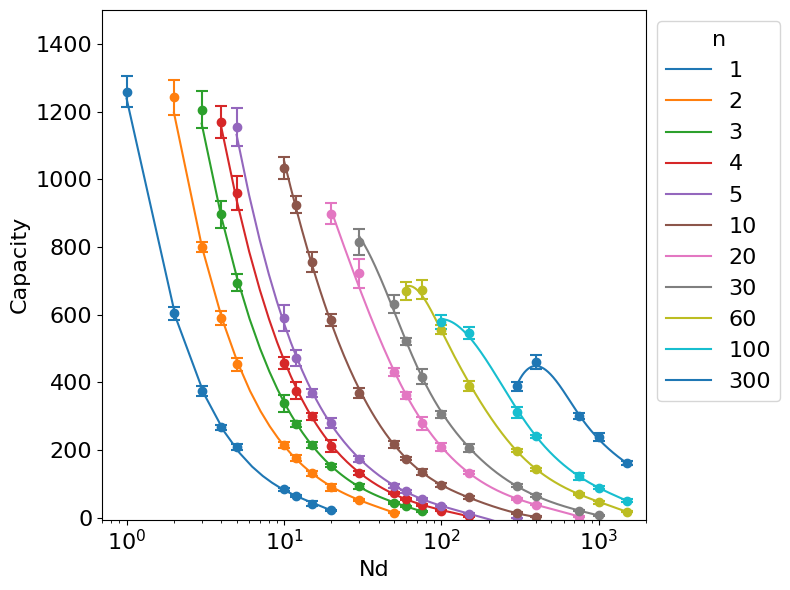

In [9]:
plt.figure(figsize=(8, 6))

for ndR_idx, ndR_value in enumerate(ndRlist):
# for ndR_idx, ndR_value in enumerate([1, 2, 3, 4, 5, 10]):
    subset = df[df['ndR'] == ndR_value]
    subset= subset.loc[subset.groupby(['capacity', 'nd'])['b'].idxmax()]
    subset = subset.sort_values("nd")
    max_nd = subset['nd'].max()
    min_nd = subset['nd'].min()
    nd_plot_list = np.linspace(min_nd, max_nd, int(max_nd-min_nd))
    try:
        xs = np.log(subset['nd'].to_numpy())
        ys = subset['capacity'].to_numpy()
        y_sem = subset['sem'].to_numpy()
        spline = smooth_spline(np.log(subset['nd'].to_numpy()), subset['capacity'].to_numpy(), y_sem)
        fitted_capacity = spline(np.log(nd_plot_list))

        # print(spline.get_coeffs())

        plt.plot(nd_plot_list, fitted_capacity, label=f"{ndR_value}", c=f"C{ndR_idx}")
    except: pass

    plt.errorbar(
        x=subset['nd'],
        y=subset['capacity'],
        yerr=2.571*subset['sem'], 
        fmt='o',  
        capsize=4,
        capthick=1.5,
        elinewidth=1.5, 
        c=f"C{ndR_idx}"
    )

# Set x-axis to log scale
plt.xscale('log')

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

plt.ylim(-5, 1500)
plt.xlim(0.7, 2000)

# Add labels and title
plt.xlabel('Nd', fontsize=16)
plt.ylabel('Capacity', fontsize=16)

# Move legend outside the plot
plt.legend(bbox_to_anchor=(1.0, 1), loc='upper left', title='n', fontsize=16, title_fontsize=16)

# plt.savefig("capacity_vs_nd_rhomax.svg", bbox_inches='tight')

plt.tight_layout()

### Single Grid Search Plot: one $n$, different coeff's

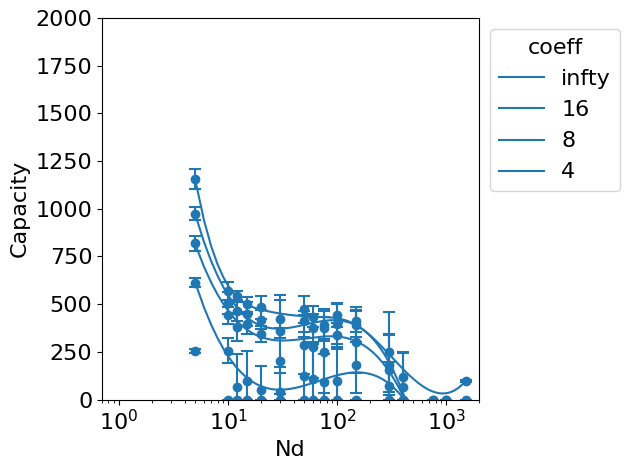

In [12]:
# file_path_list = ["../data/gridSearch_standard/60000/coeff_infty/max_points_df.csv", 
#                   "../data/gridSearch_standard/60000/coeff_16/max_points_df.csv", 
#                   "../data/gridSearch_standard/60000/coeff_8/max_points_df.csv", 
#                   "../data/gridSearch_standard/60000/coeff_4/max_points_df.csv", 
#                   "../data/gridSearch_standard/60000/coeff_1/max_points_df.csv"]

file_path_list = ["../data/gridSearch_NonInt/60000/coeff_infty/max_points_df.csv", 
                  "../data/gridSearch_NonInt/60000/coeff_16/max_points_df.csv", 
                  "../data/gridSearch_NonInt/60000/coeff_8/max_points_df.csv", 
                  "../data/gridSearch_NonInt/60000/coeff_4/max_points_df.csv", 
                  "../data/gridSearch_NonInt/60000/coeff_1/max_points_df.csv"]

# df_name_list = ["infty", "16", "8", "4", "1"]
df_name_list = ["infty", "16", "8", "4", "1"]

dfs = [pd.read_csv(file_path) for file_path in file_path_list]

ndR_value = 5
ndR_idx = 0

for df_idx, df_name in enumerate(df_name_list):
    df = dfs[df_idx]
    subset = df[df['ndR'] == ndR_value]
    subset= subset.loc[subset.groupby(['capacity', 'nd'])['b'].idxmax()]
    subset = subset.sort_values("nd")
    max_nd = subset['nd'].max()
    min_nd = subset['nd'].min()
    nd_plot_list = np.linspace(min_nd, max_nd, int(max_nd-min_nd))
    try:
        xs = np.log(subset['nd'].to_numpy())
        ys = subset['capacity'].to_numpy()
        y_sem = subset['sem'].to_numpy()
        spline = smooth_spline(np.log(subset['nd'].to_numpy()), subset['capacity'].to_numpy(), y_sem)
        fitted_capacity = spline(np.log(nd_plot_list))

        # print(spline.get_coeffs())

        plt.plot(nd_plot_list, fitted_capacity, label=f"{df_name}", c=f"C{ndR_idx}")
    except: pass

    plt.errorbar(
        x=subset['nd'],
        y=subset['capacity'],
        yerr=2.571*subset['sem'], 
        fmt='o',  
        capsize=4,
        capthick=1.5,
        elinewidth=1.5, 
        c=f"C{ndR_idx}"
    )

# Set x-axis to log scale
plt.xscale('log')

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

plt.ylim(0, 2000)
plt.xlim(0.7, 2000)

# Add labels and title
plt.xlabel('Nd', fontsize=16)
plt.ylabel('Capacity', fontsize=16)

# Move legend outside the plot
plt.legend(bbox_to_anchor=(1.0, 1), loc='upper left', title='coeff', fontsize=16, title_fontsize=16)

# plt.savefig("capacity_vs_nd_rhomax.svg", bbox_inches='tight')

plt.tight_layout()

### Multi Grid Search Plot: different $n$'s, different coeff's

Text(0.02, 0.5, 'Capacity')

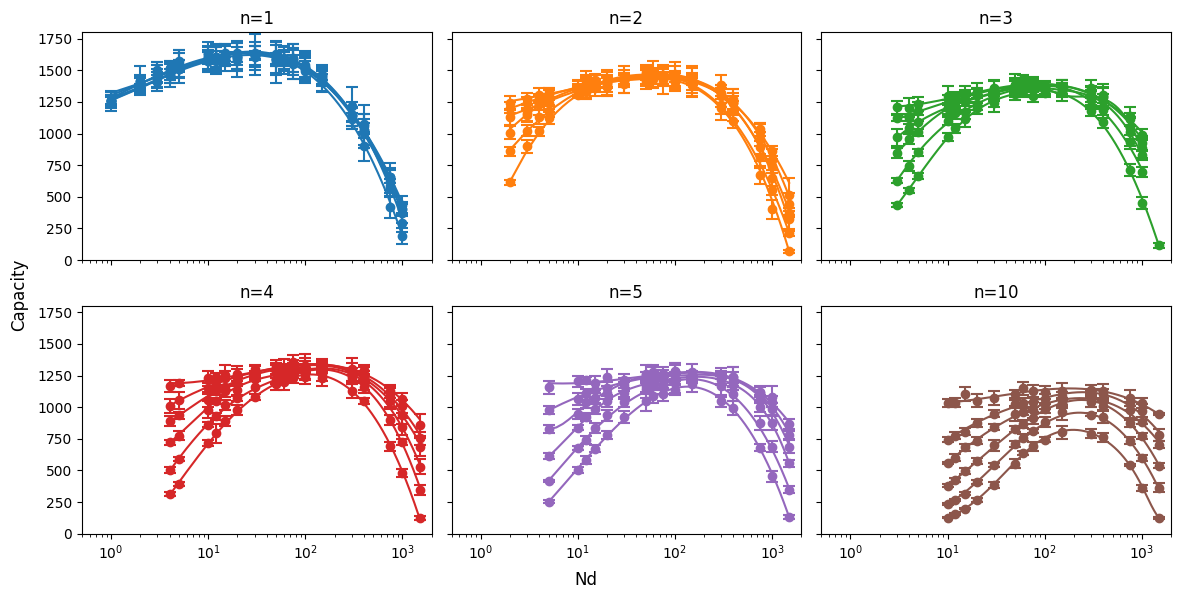

In [19]:
file_path_list = ["../data/gridSearch_standard/60000/coeff_infty/max_points_df.csv", 
                  "../data/gridSearch_standard/60000/coeff_16/max_points_df.csv", 
                  "../data/gridSearch_standard/60000/coeff_8/max_points_df.csv", 
                  "../data/gridSearch_standard/60000/coeff_4/max_points_df.csv", 
                  "../data/gridSearch_standard/60000/coeff_2/max_points_df.csv",
                  "../data/gridSearch_standard/60000/coeff_1/max_points_df.csv"]

# file_path_list = ["../data/gridSearch_NonInt/60000/coeff_infty/max_points_df.csv", 
#                   "../data/gridSearch_NonInt/60000/coeff_16/max_points_df.csv", 
#                   "../data/gridSearch_NonInt/60000/coeff_8/max_points_df.csv", 
#                   "../data/gridSearch_NonInt/60000/coeff_4/max_points_df.csv", 
#                   "../data/gridSearch_NonInt/60000/coeff_1/max_points_df.csv"]

# df_name_list = ["infty", "16", "8", "4", "1"]
df_name_list = ["infty", "16", "8", "4", "2", "1"]

dfs = [pd.read_csv(file_path) for file_path in file_path_list]
fig, ax = plt.subplots(2, 3, sharex=True, sharey=True, figsize=(12, 6))
ndRlist = [1, 2, 3, 4, 5, 10]
# ndRlist = [5, 10, 15, 20]

for ndR_idx, ndR_value in enumerate(ndRlist):
    ax_i = ndR_idx//3
    ax_j = ndR_idx%3
    for df_idx, df_name in enumerate(df_name_list):
        df = dfs[df_idx]
        subset = df[df['ndR'] == ndR_value]
        subset= subset.loc[subset.groupby(['capacity', 'nd'])['b'].idxmax()]
        subset = subset.sort_values("nd")
        max_nd = subset['nd'].max()
        min_nd = subset['nd'].min()
        nd_plot_list = np.linspace(min_nd, max_nd, int(max_nd-min_nd))
        try:
            xs = np.log(subset['nd'].to_numpy())
            ys = subset['capacity'].to_numpy()
            y_sem = subset['sem'].to_numpy()
            spline = smooth_spline(np.log(subset['nd'].to_numpy()), subset['capacity'].to_numpy(), y_sem)
            fitted_capacity = spline(np.log(nd_plot_list))

            # print(spline.get_coeffs())

            ax[ax_i, ax_j].plot(nd_plot_list, fitted_capacity, label=f"{df_name}", c=f"C{ndR_idx}")
        except: pass

        ax[ax_i, ax_j].errorbar(
            x=subset['nd'],
            y=subset['capacity'],
            yerr=2.571*subset['sem'], 
            fmt='o',  
            capsize=4,
            capthick=1.5,
            elinewidth=1.5, 
            c=f"C{ndR_idx}"
        )

    ax[ax_i, ax_j].set_xlim(0.5, 2000)
    ax[ax_i, ax_j].set_ylim(0, 1800)
    # ax[ax_i, ax_j].set_xlabel("Nd")
    # ax[ax_i, ax_j].set_ylabel("capacity")
    ax[ax_i, ax_j].set_xscale("log")
    ax[ax_i, ax_j].set_title(f"n={ndR_value}") 
plt.tight_layout(rect=(0.03,0.03,1,1))
fig.supxlabel("Nd")
fig.supylabel("Capacity")
